# TP3 - Análisis de las tablas

La idea es mirar primero qué información tenemos en cada tabla y después ver cómo relacionarlas sin usar datos del futuro. La unidad principal va a ser la solicitud: cuando terminemos de preparar los datos tiene que quedar una fila por solicitud.

In [24]:
import pandas as pd
import numpy as np

solicitudes_train = pd.read_csv("data/solicitudes_train.csv")
comportamiento_bancario = pd.read_csv("data/comportamiento_bancario.csv")

## Solicitudes de préstamos

Cada fila representa una solicitud. `ID_Solicitud` identifica la solicitud y `ID_Usuario` nos va a permitir relacionarla con el historial bancario.

In [25]:
solicitudes_train.head()

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final
0,1,12698,7900,0.2333,4461,Consumo,2025-04,1
1,2,20744,17400,0.2507,3889,Vivienda,2025-12,1
2,3,6830,8600,0.2368,4035,Vehiculo,2025-06,0
3,4,5722,13300,0.2826,4018,Vehiculo,2025-07,1
4,5,24719,6600,0.2314,3357,Otros,2025-01,1


In [26]:
solicitudes_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 32416 entries, 0 to 32415
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID_Solicitud      32416 non-null  int64  
 1   ID_Usuario        32416 non-null  int64  
 2   Monto_Solicitado  32416 non-null  int64  
 3   Tasa_Interes      32416 non-null  float64
 4   Ingreso_Mensual   32416 non-null  int64  
 5   Motivo_Prestamo   32416 non-null  str    
 6   Fecha_Solicitud   32416 non-null  str    
 7   Estado_Final      32416 non-null  int64  
dtypes: float64(1), int64(5), str(2)
memory usage: 2.4 MB


Primero revisamos la cantidad de usuarios, si hay duplicados o datos faltantes y qué período cubren las solicitudes. También pasamos la fecha al tipo correcto para poder compararla más adelante con los meses del historial bancario.

In [27]:
solicitudes_train["Fecha_Solicitud"] = pd.to_datetime(
    solicitudes_train["Fecha_Solicitud"]
)

print("Usuarios distintos:", solicitudes_train["ID_Usuario"].nunique())

print("Filas duplicadas:", solicitudes_train.duplicated().sum())


print("\nPeríodo:", solicitudes_train["Fecha_Solicitud"].min().date(),
      "a", solicitudes_train["Fecha_Solicitud"].max().date())

print("Máximo de solicitudes de un usuario:",
      solicitudes_train.groupby("ID_Usuario").size().max())

Usuarios distintos: 18548
Filas duplicadas: 0

Período: 2025-01-01 a 2025-12-01
Máximo de solicitudes de un usuario: 8


### Variables numéricas

idea general de los montos solicitados, los ingresos y las tasas de interés.

In [28]:
solicitudes_train[[
    "Monto_Solicitado",
    "Ingreso_Mensual",
    "Tasa_Interes"
]].describe()

,Monto_Solicitado,Ingreso_Mensual,Tasa_Interes
count,32416.000000,32416.000000,32416.000000
mean,14290.097483,4214.475938,0.259580
std,12995.295179,2498.904569,0.032333
min,500.000000,353.000000,0.147600
25%,5700.000000,2481.000000,0.237300
50%,10200.000000,3621.000000,0.258300
75%,18100.000000,5276.000000,0.280600
max,70000.000000,22000.000000,0.379900


### Relación entre el préstamo y el ingreso

comparando el ingreso mensual de la persona con el monto del prestamos sacamos un ratio, entre más alto significa que el préstamo representa varios meses de ingreso y podría ser más difícil de pagar.

In [29]:
solicitudes_train["ratio_prestamo_ingreso"] = (
    solicitudes_train["Monto_Solicitado"]
    / solicitudes_train["Ingreso_Mensual"]
)

solicitudes_train[[
    "ID_Solicitud",
    "ID_Usuario",
    "Monto_Solicitado",
    "Ingreso_Mensual",
    "ratio_prestamo_ingreso"
]]

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Ingreso_Mensual,ratio_prestamo_ingreso
0,1,12698,7900,4461,1.770903
1,2,20744,17400,3889,4.474158
2,3,6830,8600,4035,2.131351
3,4,5722,13300,4018,3.310105
4,5,24719,6600,3357,1.966041
...,...,...,...,...,...
32411,32412,22337,38600,7654,5.043115
32412,32413,15817,4700,1388,3.386167
32413,32414,330,5000,2445,2.044990
32414,32415,2907,28600,8412,3.399905


### Estado final

`Estado_Final` es lo que más adelante queremos predecir: 1 significa que el préstamo fue pagado y 0 que terminó en default. vemos si las dos clases están equilibradas.

In [30]:
solicitudes_train["Estado_Final"].value_counts(normalize=True).sort_index() * 100

Estado_Final
0    15.951999
1    84.048001
Name: proportion, dtype: float64

### Motivo del préstamo

podemos mirar por tipo de categoria que "porcentaje" de pago tiene, capaz no cambia mucho pero bueno, todo sirve

In [31]:
porcentaje_pago_por_motivo = (
    solicitudes_train.groupby("Motivo_Prestamo")["Estado_Final"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

porcentaje_pago_por_motivo

Motivo_Prestamo
Educacion    85.990712
Vivienda     85.939941
Salud        85.610264
Consumo      83.677754
Otros        82.909640
Vehiculo     82.612782
Negocio      80.626672
Name: Estado_Final, dtype: float64

### Tasa de interés

La tasa promedio cambia poco entre los préstamos pagados y los que terminaron en default, por sí sola tal vez no aporta mucho, pero la vamos a necesitar para calcular la ganancia esperada.

In [32]:
solicitudes_train.groupby("Estado_Final")["Tasa_Interes"].mean().sort_index()

Estado_Final
0    0.267905
1    0.258000
Name: Tasa_Interes, dtype: float64

## Comportamiento bancario
esta tabla cada fila representa un mes de un usuario. Por eso tiene muchas más filas que la tabla de solicitudes.

In [33]:
comportamiento_bancario.head()

,ID_Usuario,Mes_Referencia,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas
0,1,2024-01,12768.11,3
1,1,2024-02,15817.67,3
2,1,2024-03,13138.66,0
3,1,2024-04,19453.13,0
4,1,2024-05,14943.44,59


In [34]:
comportamiento_bancario.info()

<class 'pandas.DataFrame'>
RangeIndex: 661139 entries, 0 to 661138
Data columns (total 4 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID_Usuario                661139 non-null  int64  
 1   Mes_Referencia            661139 non-null  str    
 2   Saldo_Promedio_Mensual    661139 non-null  float64
 3   Dias_Atraso_Otras_Deudas  661139 non-null  int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 24.6 MB


Pasamos `Mes_Referencia` a fecha y revisamos usuarios, duplicados, valores faltantes y cantidad de meses disponibles.

In [35]:
comportamiento_bancario["Mes_Referencia"] = pd.to_datetime(
    comportamiento_bancario["Mes_Referencia"]
)

print("Usuarios distintos:", comportamiento_bancario["ID_Usuario"].nunique())
print("Período:", comportamiento_bancario["Mes_Referencia"].min().date(),
      "a", comportamiento_bancario["Mes_Referencia"].max().date())

meses_por_usuario = comportamiento_bancario.groupby(
    "ID_Usuario"
)["Mes_Referencia"].nunique()

print("\nMeses disponibles por usuario:")
display(meses_por_usuario.describe().round(2))

Usuarios distintos: 28993
Período: 2024-01-01 a 2025-12-01

Meses disponibles por usuario:


count    28993.00
mean        22.80
std          1.07
min         17.00
25%         22.00
50%         23.00
75%         24.00
max         24.00
Name: Mes_Referencia, dtype: float64

### Saldos y atrasos

`Saldo_Promedio_Mensual` no es el sueldo de la persona: es el saldo promedio que mantuvo en la cuenta durante ese mes. Nos puede servir para ver su situación y si viene mejorando o empeorando. Los días de atraso muestran cómo se comportó con otras deudas.

In [36]:
comportamiento_bancario[[
    "Saldo_Promedio_Mensual",
    "Dias_Atraso_Otras_Deudas"
]].describe()

,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas
count,661139.000000,661139.000000
mean,5463.296614,8.950755
std,5473.861364,13.199638
min,3.300000,0.000000
25%,2061.955000,1.000000
50%,3974.280000,5.000000
75%,7082.925000,10.000000
max,165915.350000,90.000000


Como exploración podemos resumir el historial completo de cada usuario para ver qué características podrían servir: saldo promedio, saldo inicial, saldo final, cambio del saldo y atrasos. Este resumen todavía no se usa para entrenar porque incluye meses que podrían ser posteriores a una solicitud.

In [37]:
banco_ordenado = comportamiento_bancario.sort_values(
    ["ID_Usuario", "Mes_Referencia"]
)

resumen_exploratorio_banco = banco_ordenado.groupby("ID_Usuario").agg(
    meses_disponibles=("Mes_Referencia", "count"),
    saldo_promedio=("Saldo_Promedio_Mensual", "mean"),
    saldo_inicial=("Saldo_Promedio_Mensual", "first"),
    saldo_final=("Saldo_Promedio_Mensual", "last"),
    atraso_promedio=("Dias_Atraso_Otras_Deudas", "mean"),
    atraso_maximo=("Dias_Atraso_Otras_Deudas", "max")
)

resumen_exploratorio_banco["cambio_saldo"] = (
    resumen_exploratorio_banco["saldo_final"]
    - resumen_exploratorio_banco["saldo_inicial"]
)

resumen_exploratorio_banco.head()

,meses_disponibles,saldo_promedio,saldo_inicial,saldo_final,atraso_promedio,atraso_maximo,cambio_saldo
ID_Usuario,,,,,,,
1,23,20017.683913,12768.11,23343.81,8.304348,59,10575.70
2,21,3781.878571,3335.41,4576.35,16.619048,67,1240.94
3,22,4577.649545,4683.17,4133.35,1.090909,4,-549.82
4,24,4992.794583,3971.51,6122.52,1.958333,18,2151.01
5,24,2556.866667,3738.41,1753.87,27.000000,70,-1984.54


## Relacionar las tablas

No podemos unir y dejar las tablas así nomás porque una solicitud se repetiría una vez por cada mes bancario del usuario. Primero hacemos esa unión para relacionar los registros, después sacamos los meses futuros y finalmente vamos a resumir el historial de cada solicitud.

### Paso 1: unir por usuario

aca van a aumentar mucho la cantidad de filas ya que cada solicitud queda repetida por todos los meses bancarios de su usuario.

In [38]:
historial_solicitudes = solicitudes_train.merge(
    comportamiento_bancario,
    on="ID_Usuario",
    how="left"
)

print("Filas de solicitudes:", len(solicitudes_train))
print("Filas después del merge:", len(historial_solicitudes))

Filas de solicitudes: 32416
Filas después del merge: 739137


### Paso 2: conservar solamente los meses anteriores

ver de usar la información que ya existía en ese momento. Si usáramos meses posteriores estaríamos mirando el futuro. Como las fechas indican solamente el mes, también dejamos afuera el mismo mes de la solicitud.

In [39]:
historial_solicitudes = historial_solicitudes[
    historial_solicitudes["Mes_Referencia"]
    < historial_solicitudes["Fecha_Solicitud"]
].copy()

print("Filas después del filtro temporal:", len(historial_solicitudes))
print("Solicitudes distintas:", historial_solicitudes["ID_Solicitud"].nunique())

Filas después del filtro temporal: 538638
Solicitudes distintas: 32416


Todavía hay varias filas por solicitud, una por cada mes anterior. El próximo paso va a ser resumir esos meses por `ID_Solicitud` para volver a tener una sola fila por préstamo.

In [40]:
historial_solicitudes

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final,ratio_prestamo_ingreso,Mes_Referencia,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas
0,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,2024-01-01,3712.29,2
1,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,2024-02-01,3749.28,25
2,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,2024-03-01,3510.29,3
3,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,2024-04-01,3997.29,1
4,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,2024-05-01,3304.99,7
...,...,...,...,...,...,...,...,...,...,...,...,...
739122,32416,19379,10400,0.2455,9327,Educacion,2025-03-01,1,1.115042,2024-10-01,13248.54,0
739123,32416,19379,10400,0.2455,9327,Educacion,2025-03-01,1,1.115042,2024-11-01,15281.30,4
739124,32416,19379,10400,0.2455,9327,Educacion,2025-03-01,1,1.115042,2024-12-01,13933.95,0
739125,32416,19379,10400,0.2455,9327,Educacion,2025-03-01,1,1.115042,2025-01-01,17164.54,0


### Paso 3: resumir el historial por solicitud

Ahora agrupamos por `ID_Solicitud`, porque un mismo usuario puede haber pedido varios préstamos en fechas distintas. Guardamos la cantidad de meses, el saldo promedio, el último saldo conocido, la evolución del saldo y el comportamiento de los atrasos.

In [41]:
historial_ordenado = historial_solicitudes.sort_values(
    ["ID_Solicitud", "Mes_Referencia"]
)

resumen_historial = historial_ordenado.groupby("ID_Solicitud").agg(
    meses_historial=("Mes_Referencia", "count"),
    saldo_promedio=("Saldo_Promedio_Mensual", "mean"),
    saldo_inicial=("Saldo_Promedio_Mensual", "first"),
    saldo_final=("Saldo_Promedio_Mensual", "last"),
    atraso_promedio=("Dias_Atraso_Otras_Deudas", "mean"),
    atraso_maximo=("Dias_Atraso_Otras_Deudas", "max")
).reset_index()

resumen_historial.head()

,ID_Solicitud,meses_historial,saldo_promedio,saldo_inicial,saldo_final,atraso_promedio,atraso_maximo
0,1,14,3695.225714,3712.29,3352.35,4.857143,25
1,2,21,5976.456667,3807.48,5054.62,8.809524,56
2,3,15,178.574667,203.23,178.46,20.733333,57
3,4,18,7589.356667,6543.97,7372.57,0.944444,4
4,5,12,3888.616667,4848.48,2952.59,3.750000,32


### Paso 4: volver a una fila por solicitud y crear los ratios

Volvemos a unir el resumen con las solicitudes. El ratio de tendencia compara el último saldo con el primero: un valor mayor que 1 indica una suba y uno menor que 1 una baja. También comparamos el monto solicitado con el ingreso y con el saldo promedio. Las variables originales se conservan porque el ratio solo no muestra la escala de los montos.

In [42]:
datos_modelo = solicitudes_train.merge(
    resumen_historial,
    on="ID_Solicitud",
    how="left",
    validate="one_to_one"
)

saldo_inicial_seguro = datos_modelo["saldo_inicial"].mask(
    datos_modelo["saldo_inicial"].eq(0)
)
saldo_promedio_seguro = datos_modelo["saldo_promedio"].mask(
    datos_modelo["saldo_promedio"].eq(0)
)

datos_modelo["ratio_tendencia_saldo"] = (
    datos_modelo["saldo_final"] / saldo_inicial_seguro
)
datos_modelo["ratio_prestamo_ingreso"] = (
    datos_modelo["Monto_Solicitado"] / datos_modelo["Ingreso_Mensual"]
)
datos_modelo["ratio_prestamo_saldo"] = (
    datos_modelo["Monto_Solicitado"] / saldo_promedio_seguro
)

datos_modelo = datos_modelo.drop(columns="saldo_inicial")

print("Filas del dataset preparado:", len(datos_modelo))
print("Solicitudes distintas:", datos_modelo["ID_Solicitud"].nunique())
datos_modelo.head()

Filas del dataset preparado: 32416
Solicitudes distintas: 32416


,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final,ratio_prestamo_ingreso,meses_historial,saldo_promedio,saldo_final,atraso_promedio,atraso_maximo,ratio_tendencia_saldo,ratio_prestamo_saldo
0,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,14,3695.225714,3352.35,4.857143,25,0.903041,2.137894
1,2,20744,17400,0.2507,3889,Vivienda,2025-12-01,1,4.474158,21,5976.456667,5054.62,8.809524,56,1.327550,2.911424
2,3,6830,8600,0.2368,4035,Vehiculo,2025-06-01,0,2.131351,15,178.574667,178.46,20.733333,57,0.878118,48.159127
3,4,5722,13300,0.2826,4018,Vehiculo,2025-07-01,1,3.310105,18,7589.356667,7372.57,0.944444,4,1.126620,1.752454
4,5,24719,6600,0.2314,3357,Otros,2025-01-01,1,1.966041,12,3888.616667,2952.59,3.750000,32,0.608972,1.697262


para el modelo el objetivo va a ser Estado_Final, excluiriamos el Id_Solicitud e Id_Usuario, ver de transformar Motivo_Prestamo (que es categorica), en el tema del mes podemos verla de excluir, separar por los id de los usuarios para que no aparezcan en el entrenamiento y validacion.

In [43]:
print("Cantidad de filas:", len(datos_modelo))
print("Solicitudes distintas:", datos_modelo["ID_Solicitud"].nunique())
print("IDs repetidos:", datos_modelo["ID_Solicitud"].duplicated().sum())

Cantidad de filas: 32416
Solicitudes distintas: 32416
IDs repetidos: 0


In [44]:
datos_modelo.isnull().sum().sort_values(ascending=False)

ID_Solicitud              0
ID_Usuario                0
Monto_Solicitado          0
Tasa_Interes              0
Ingreso_Mensual           0
Motivo_Prestamo           0
Fecha_Solicitud           0
Estado_Final              0
ratio_prestamo_ingreso    0
meses_historial           0
saldo_promedio            0
saldo_final               0
atraso_promedio           0
atraso_maximo             0
ratio_tendencia_saldo     0
ratio_prestamo_saldo      0
dtype: int64

In [45]:
np.isinf(
    datos_modelo.select_dtypes(include="number")
).sum().sort_values(ascending=False)

ID_Solicitud              0
ID_Usuario                0
Monto_Solicitado          0
Tasa_Interes              0
Ingreso_Mensual           0
Estado_Final              0
ratio_prestamo_ingreso    0
meses_historial           0
saldo_promedio            0
saldo_final               0
atraso_promedio           0
atraso_maximo             0
ratio_tendencia_saldo     0
ratio_prestamo_saldo      0
dtype: int64

In [46]:
datos_modelo[[
    "ratio_prestamo_ingreso",
    "ratio_prestamo_saldo",
    "ratio_tendencia_saldo"
]].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99])

,ratio_prestamo_ingreso,ratio_prestamo_saldo,ratio_tendencia_saldo
count,32416.000000,32416.000000,32416.000000
mean,3.439613,14.551608,1.105596
std,2.425354,73.067997,0.539219
min,0.123122,0.068209,0.113253
1%,0.612282,0.359758,0.324540
5%,0.964803,0.623646,0.465906
50%,2.799969,2.522912,1.002416
95%,8.166632,28.115860,2.093306
99%,12.217510,342.112035,2.960705
max,55.142018,1897.614428,8.252326


In [47]:
datos_modelo["log_ratio_prestamo_ingreso"] = np.log1p(
    datos_modelo["ratio_prestamo_ingreso"]
)

datos_modelo["log_ratio_prestamo_saldo"] = np.log1p(
    datos_modelo["ratio_prestamo_saldo"]
)

datos_modelo["log_ratio_tendencia_saldo"] = np.log(
    datos_modelo["ratio_tendencia_saldo"]
)

In [48]:
datos_modelo


,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final,ratio_prestamo_ingreso,meses_historial,saldo_promedio,saldo_final,atraso_promedio,atraso_maximo,ratio_tendencia_saldo,ratio_prestamo_saldo,log_ratio_prestamo_ingreso,log_ratio_prestamo_saldo,log_ratio_tendencia_saldo
0,1,12698,7900,0.2333,4461,Consumo,2025-04-01,1,1.770903,14,3695.225714,3352.35,4.857143,25,0.903041,2.137894,1.019173,1.143552,-0.101987
1,2,20744,17400,0.2507,3889,Vivienda,2025-12-01,1,4.474158,21,5976.456667,5054.62,8.809524,56,1.327550,2.911424,1.700038,1.363902,0.283335
2,3,6830,8600,0.2368,4035,Vehiculo,2025-06-01,0,2.131351,15,178.574667,178.46,20.733333,57,0.878118,48.159127,1.141464,3.895063,-0.129974
3,4,5722,13300,0.2826,4018,Vehiculo,2025-07-01,1,3.310105,18,7589.356667,7372.57,0.944444,4,1.126620,1.752454,1.460962,1.012493,0.119222
4,5,24719,6600,0.2314,3357,Otros,2025-01-01,1,1.966041,12,3888.616667,2952.59,3.750000,32,0.608972,1.697262,1.087228,0.992237,-0.495983
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32411,32412,22337,38600,0.2640,7654,Vivienda,2025-04-01,1,5.043115,13,10926.146154,7144.53,4.846154,38,0.599719,3.532810,1.798920,1.511342,-0.511293
32412,32413,15817,4700,0.2872,1388,Otros,2025-10-01,0,3.386167,19,504.819474,359.29,19.421053,65,0.519942,9.310259,1.478456,2.333139,-0.654039
32413,32414,330,5000,0.2699,2445,Vehiculo,2025-05-01,1,2.044990,16,2730.808125,2381.08,10.125000,15,0.767929,1.830960,1.113498,1.040616,-0.264058
32414,32415,2907,28600,0.2907,8412,Negocio,2025-02-01,1,3.399905,12,15493.373333,15278.24,4.666667,48,1.112332,1.845950,1.481583,1.045897,0.106459


grafico para ver como quedo el grafico normalizado con la funcion logaritmica

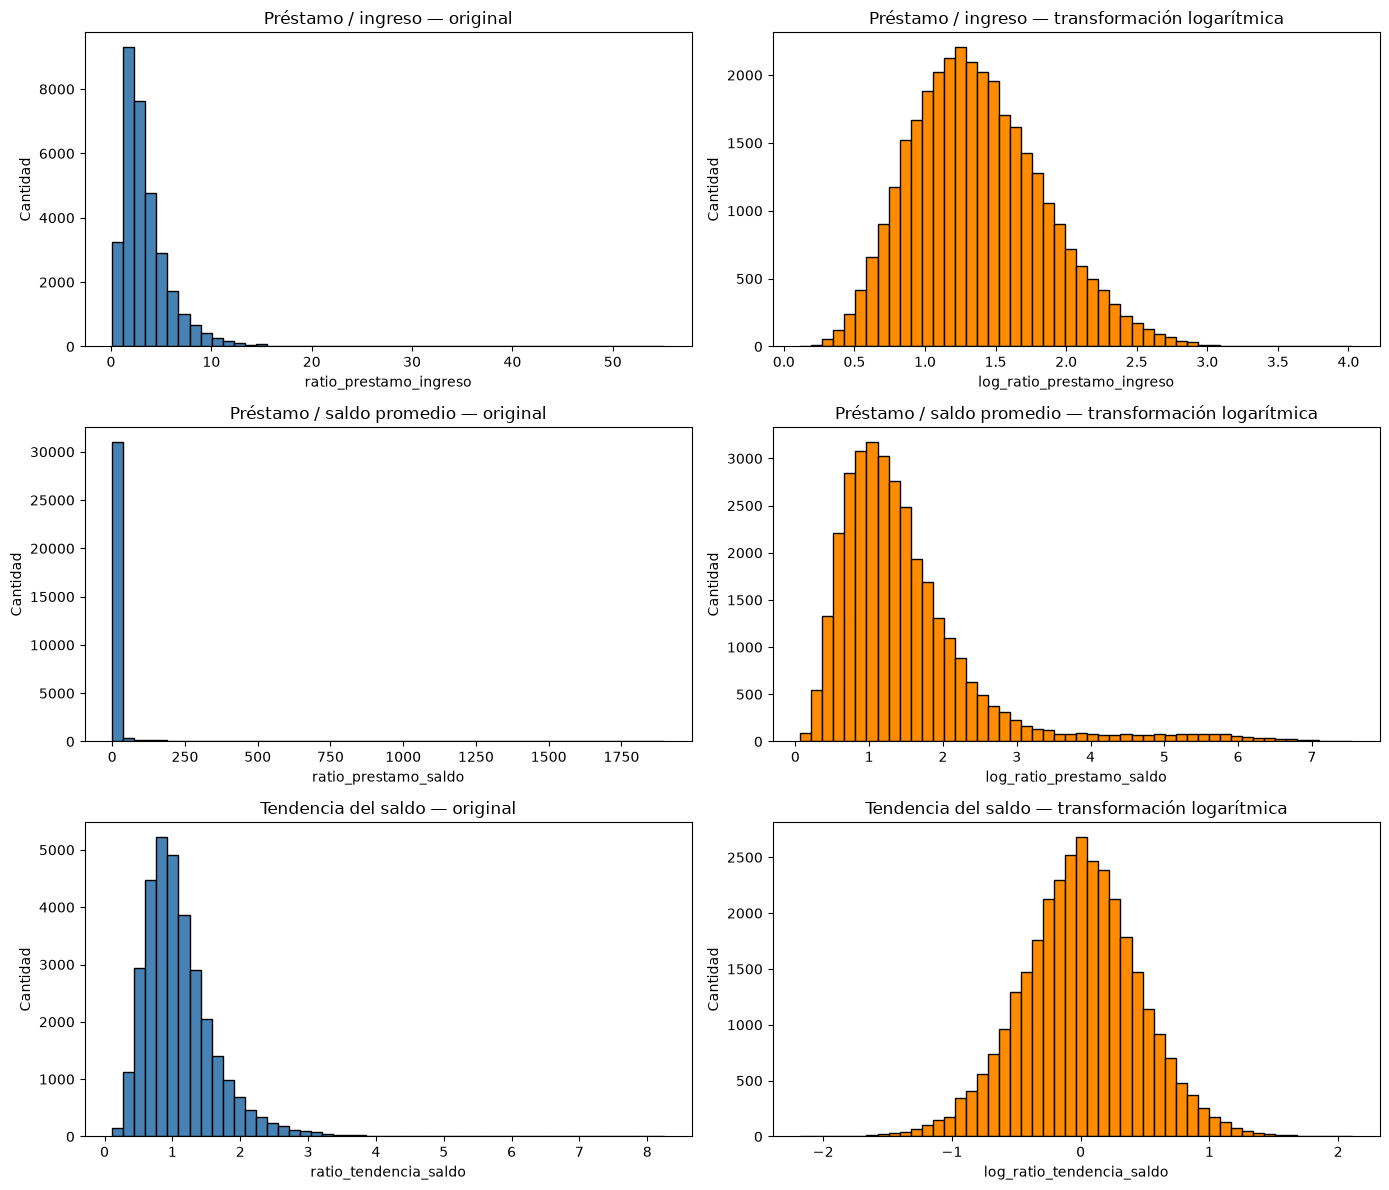

In [49]:
import matplotlib.pyplot as plt

comparaciones = [
    (
        "ratio_prestamo_ingreso",
        "log_ratio_prestamo_ingreso",
        "Préstamo / ingreso"
    ),
    (
        "ratio_prestamo_saldo",
        "log_ratio_prestamo_saldo",
        "Préstamo / saldo promedio"
    ),
    (
        "ratio_tendencia_saldo",
        "log_ratio_tendencia_saldo",
        "Tendencia del saldo"
    )
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for fila, (original, logaritmica, titulo) in enumerate(comparaciones):

    axes[fila, 0].hist(
        datos_modelo[original].dropna(),
        bins=50,
        color="steelblue",
        edgecolor="black"
    )
    axes[fila, 0].set_title(f"{titulo} — original")
    axes[fila, 0].set_xlabel(original)
    axes[fila, 0].set_ylabel("Cantidad")

    axes[fila, 1].hist(
        datos_modelo[logaritmica].dropna(),
        bins=50,
        color="darkorange",
        edgecolor="black"
    )
    axes[fila, 1].set_title(f"{titulo} — transformación logarítmica")
    axes[fila, 1].set_xlabel(logaritmica)
    axes[fila, 1].set_ylabel("Cantidad")

plt.tight_layout()
plt.show()

verificar si en algun dato de registros bancarios tiene fecha igual o posterior a fecha_solicitud

In [50]:
(historial_solicitudes["Mes_Referencia"] < historial_solicitudes["Fecha_Solicitud"]).all()

np.True_

se le aplica One Hot Encoder a la columna categorica "Motivo_Prestamo"

In [51]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
motivo_encoded = encoder.fit_transform(datos_modelo[["Motivo_Prestamo"]])

df_motivo = pd.DataFrame(
    motivo_encoded,
    columns=encoder.get_feature_names_out(["Motivo_Prestamo"]),
    index=datos_modelo.index
)

datos_modelo = pd.concat(
    [datos_modelo.drop(columns=["Motivo_Prestamo"]), df_motivo],
    axis=1
)

datos_modelo.head()

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Fecha_Solicitud,Estado_Final,ratio_prestamo_ingreso,meses_historial,saldo_promedio,...,log_ratio_prestamo_ingreso,log_ratio_prestamo_saldo,log_ratio_tendencia_saldo,Motivo_Prestamo_Consumo,Motivo_Prestamo_Educacion,Motivo_Prestamo_Negocio,Motivo_Prestamo_Otros,Motivo_Prestamo_Salud,Motivo_Prestamo_Vehiculo,Motivo_Prestamo_Vivienda
0,1,12698,7900,0.2333,4461,2025-04-01,1,1.770903,14,3695.225714,...,1.019173,1.143552,-0.101987,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,20744,17400,0.2507,3889,2025-12-01,1,4.474158,21,5976.456667,...,1.700038,1.363902,0.283335,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,3,6830,8600,0.2368,4035,2025-06-01,0,2.131351,15,178.574667,...,1.141464,3.895063,-0.129974,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,4,5722,13300,0.2826,4018,2025-07-01,1,3.310105,18,7589.356667,...,1.460962,1.012493,0.119222,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,5,24719,6600,0.2314,3357,2025-01-01,1,1.966041,12,3888.616667,...,1.087228,0.992237,-0.495983,0.0,0.0,0.0,1.0,0.0,0.0,0.0
